# Interpretability 1: Hello, MultKAN!

Motivation: The original KAN has some level of interpretability, but sometimes not fully interpretable (fully interpretable = convert the network to a symbolic formula). The biggest limitation is the lack of multiplications operators. The original KAN only has addition operators. Although multiplication can be expressed as addition and single-variable functions (which is the core idea of Kolmogorov-Arnold representation theorem), we still hope to explicitly have multiplications in the KANs so that multiplications can be more easily read out from KANs. 

We first show how multiplications can be represented by addition and single variable functions. Usually KAN would find solutions leveraging linear functions and quadractic functions (the solutions are not unique). $$xy=((x+y)^2-(x-y)^2)/4=((x+y)^2-x^2-y^2)/2=\cdots$$

In [1]:
import torch
from sympy import nsimplify
from xkan import KANNetwork, create_dataset, fit
from xkan.interp import prune
from xkan.symbolic import auto_symbolic, symbolic_formula
from xkan.utils import ex_round
from xkan.viz import plot

torch.set_default_dtype(torch.float64)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model = KANNetwork([2,5,1], device=device)

f = lambda x: x[:,0] * x[:,1]
train, test = create_dataset(f, n_var=2, device=device)
history = fit(model, train, test, steps=20, lamb=0.001)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.007048747702117605 test RMSE 0.007864629416852932


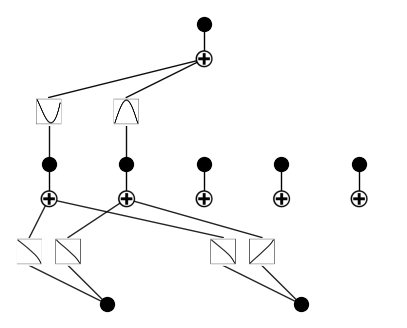

In [2]:
plot(model, train['x']);

This network seems to be using the equality $xy=((x+y)^2-(x-y)^2)/4$ but not exactly.

Next, add multiplication nodes (MultKAN). KAN and MultKAN share one implementation, `KANNetwork`; a KAN is a MultKAN without multiplication nodes. The width parameter adds them: [2,5,1] means 2 inputs, 5 hidden addition nodes and 1 output, and [2,[5,2],1] means 2 inputs, 5 hidden addition nodes, 2 hidden multiplication nodes and 1 output.

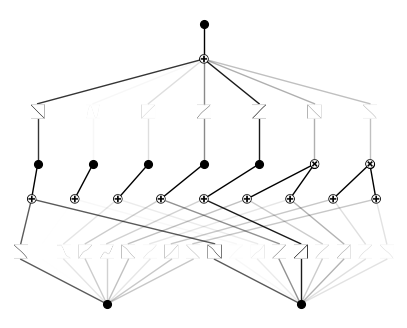

In [3]:
model = KANNetwork([2,[5,2],1], base_fun='identity', device=device)
plot(model, train['x']);

In [4]:
history = fit(model, train, test, steps=20, lamb=0.01, lamb_coef=1.0)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.015269892286396108 test RMSE 0.015919258877408148


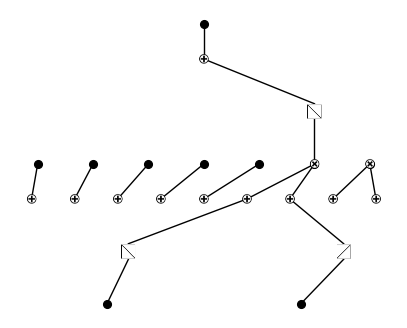

In [5]:
plot(model, train['x']);

In [6]:
model = prune(model, train['x'])
model.width

[[2, 0], [0, 1], [1, 0]]

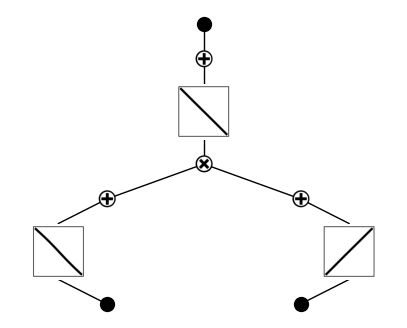

In [7]:
plot(model, train['x']);

In [8]:
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 6.170216622206928e-11 test RMSE 1.6990324382045739e-10


In [9]:
auto_symbolic(model, train['x']);

fixing (0,0,1) with 0
fixing (0,1,0) with 0


fixing (0,0,0) with x, r2=0.9999999999894452, c=1


fixing (0,1,1) with x, r2=0.9999999999913619, c=1


fixing (1,0,0) with x, r2=0.999999999919383, c=1


In [10]:
history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 1.2043412523613226e-11 test RMSE 1.2207345620234279e-11


In [11]:
sf = symbolic_formula(model)[0][0]
nsimplify(ex_round(ex_round(sf, 3),3))

x_1*x_2